# Forward learning with FASHIONMNIST0.6 dataset

In [18]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import torchvision

In [19]:
FILE_PATH = 'data/FashionMNIST0.6.npz'

## Prepare data

In [23]:
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def prepare_images(X, is_grayscale):
    X = torch.from_numpy(X).float()
    if X.max() > 1.0:                    # only scale if it's still 0-255
        X = X / 255.0

    if is_grayscale:                     # FashionMNIST: (N,28,28)
        X = X.reshape(-1, 28, 28)
        X = X.unsqueeze(1)               # -> (N,1,28,28)
        X = X.repeat(1, 3, 1, 1)         # -> (N,3,28,28)
    else:                                # CIFAR: (N,32,32,3)
        X = X.permute(0, 3, 1, 2)        # -> (N,3,32,32)

    return (X - mean) / std              # normalize

In [24]:
data = np.load(FILE_PATH)

Xtr = prepare_images(data["Xtr"], is_grayscale=True)
Xts = prepare_images(data["Xts"], is_grayscale=True)
Str = torch.from_numpy(data["Str"]).long()
Yts = torch.from_numpy(data["Yts"]).long()

In [25]:
# Random 80/20 split (change seed each run)
seed = 0
idx_tr, idx_val = train_test_split(
    np.arange(len(Xtr)), test_size=0.2, random_state=seed
)

train_loader = DataLoader(TensorDataset(Xtr[idx_tr], Str[idx_tr]), batch_size=128, shuffle=True)
val_loader   = DataLoader(TensorDataset(Xtr[idx_val], Str[idx_val]), batch_size=128)
test_loader  = DataLoader(TensorDataset(Xts, Yts), batch_size=128)

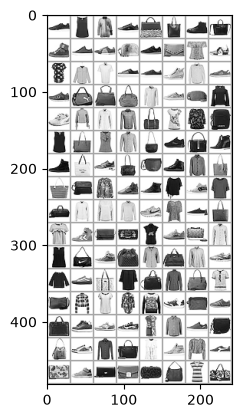

In [26]:
def matplotlib_imshow(img, one_channel=False):
    if one_channel:
        img = img.mean(dim=0)
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    if one_channel:
        plt.imshow(npimg, cmap="Greys")
    else:
        plt.imshow(np.transpose(npimg, (1, 2, 0)))

dataiter = iter(train_loader)
images, labels = next(dataiter)

# Create a grid from the images and show them
img_grid = torchvision.utils.make_grid(images)
matplotlib_imshow(img_grid, one_channel=True)

## Define model: ResNet18 (pretrained)

In [34]:
from torchvision.models import (resnet18, ResNet18_Weights)

pretrained ResNet18 was built for ImageNet (1000 classes, 3-channel 224×224 images)

change 1000 classes to 3 classes

In [47]:
model = resnet18(weights=ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 3)
#model.conv1 = nn.Conv2d(1, 64, 7, 2, 3, bias=False)

## Loss function, optimizer

In [48]:
criterion = nn.CrossEntropyLoss()           # for classification
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

## Apply Transition matrix

In [49]:
T = torch.tensor([
    [0.4, 0.3, 0.3],
    [0.3, 0.4, 0.3],
    [0.3, 0.3, 0.4],
], dtype=torch.float32)
print("Shape:", T.shape)

Shape: torch.Size([3, 3])


## Forward correction loss

In [50]:
def forward_correction_loss(logits, noisy_labels, T, epsilon=1e-8):
    p = torch.nn.functional.softmax(logits, dim=1)
    q = p @ T # noisy probabilities
    #label_column = noisy_labels.unsqueeze(1)
    log_q = torch.log(q.clamp_min(epsilon))
    loss = torch.nn.functional.nll_loss(log_q, noisy_labels)
    return loss

## Training loop

In [51]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [52]:
num_epochs = 20

for epoch in range(num_epochs):
    # ---------- Training ----------
    model.train()                      # turn on training mode
    running_loss = 0.0

    model = model.to(device)

    for epoch in range(num_epochs):
        model.train()
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)                                  # (N, 3) logits
            loss = forward_correction_loss(outputs, batch_y, T)       # your function
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        running_loss += loss.item()

    avg_train_loss = running_loss / len(train_loader)

    # ---------- Validation ----------
    model.eval()                       # turn on evaluation mode
    val_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():              # no gradients needed
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            val_loss += criterion(outputs, batch_y).item()

            preds = outputs.argmax(dim=1)
            correct += (preds == batch_y).sum().item()
            total += batch_y.size(0)

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train loss: {avg_train_loss:.4f} | "
          f"Val loss: {val_loss/len(val_loader):.4f} | "
          f"Val acc: {correct/total:.2%}")

KeyboardInterrupt: 